# Used Car Price Prediction — Business and Feature Insights

## Objective

This analysis explores relationships between vehicle characteristics and used-car selling prices. The goal is to identify patterns that may help explain price differences and guide feature selection for the machine learning model.

The analysis uses the cleaned dataset produced by the data-cleaning pipeline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

df = pd.read_csv("../data/cleaned.csv")
df["log_price"] = np.log1p(df["selling_price"])
print(df.shape)
df.head()

(6916, 15)


,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand,model,torque_nm,car_age,log_price
0,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,Maruti,Swift Dzire,190.000000,7,13.017005
1,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,Skoda,Rapid,250.000000,7,12.821261
2,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,Honda,City,124.544455,15,11.970357
3,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,Hyundai,i20,219.668960,11,12.323860
4,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,Maruti,Swift,112.776475,14,11.775297


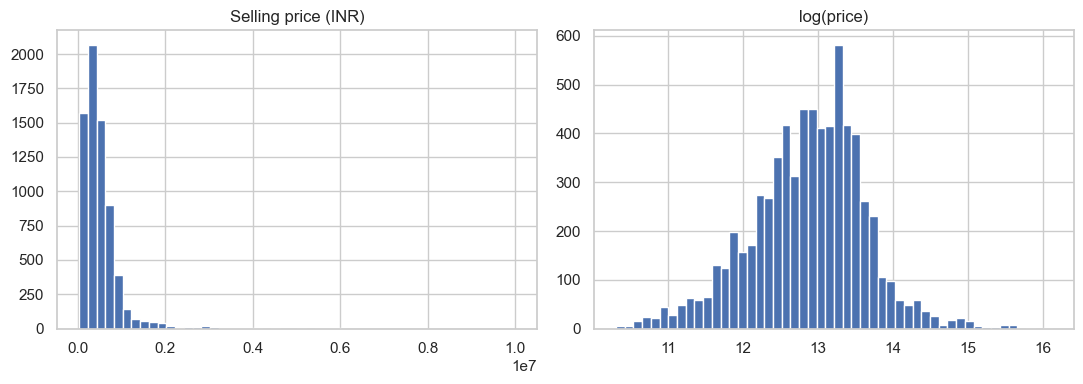

Skew (raw): 5.44
Skew (log): -0.18


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["selling_price"].hist(bins=50, ax=ax[0])
ax[0].set_title("Selling price (INR)")
df["log_price"].hist(bins=50, ax=ax[1])
ax[1].set_title("log(price)")
plt.tight_layout()
plt.show()

print("Skew (raw):", round(df["selling_price"].skew(), 2))
print("Skew (log):", round(df["log_price"].skew(), 2))

## 1. Relationship Between Car Age and Selling Price

Car age represents the number of years since the vehicle was manufactured.

Car age is calculated during data cleaning as the difference between a reference year and the vehicle's manufacturing year.

A boxplot is used to compare the distribution of selling prices across different car ages.

A general decrease in median selling price with increasing car age would indicate depreciation, meaning that vehicles tend to lose market value as they become older.

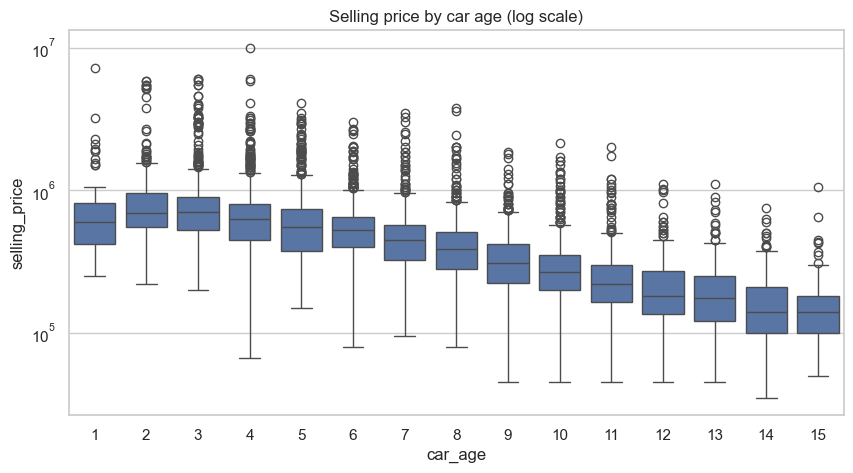

car_age
1     600000.0
2     690000.0
3     700000.0
4     625000.0
5     550000.0
6     525000.0
7     450000.0
8     387000.0
9     310000.0
10    265000.0
11    220000.0
12    180000.0
Name: selling_price, dtype: float64

In [3]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df["car_age"] <= 15], x="car_age", y="selling_price")
plt.yscale("log")
plt.title("Selling price by car age (log scale)")
plt.show()

med_age = df.groupby("car_age")["selling_price"].median()
med_age.head(12).round(0)

In [4]:
p1, p8 = med_age.get(1), med_age.get(8)
if p1 and p8:
    yearly = 1 - (p8 / p1) ** (1 / 7)
    print(f"Median price drops about {yearly:.1%} per year between ages 1 and 8")

Median price drops about 6.1% per year between ages 1 and 8


### Estimated Annual Depreciation

The annual depreciation estimate compares the median selling price of 1-year-old cars with that of 8-year-old cars.

The calculation provides an approximate compound annual rate of price decline over this seven-year interval. This is an exploratory estimate rather than a formal depreciation model, because used-car prices are also affected by factors such as brand, model, mileage, fuel type, transmission, engine, and vehicle condition.

## 2. Selling Price by Brand

Brand is an important categorical feature because different manufacturers may have different pricing patterns in the used-car market.

The median selling price is compared across brands to reduce the influence of extremely expensive or inexpensive listings.

Only brands with at least 30 listings are included in the comparison to reduce the effect of very small sample sizes.

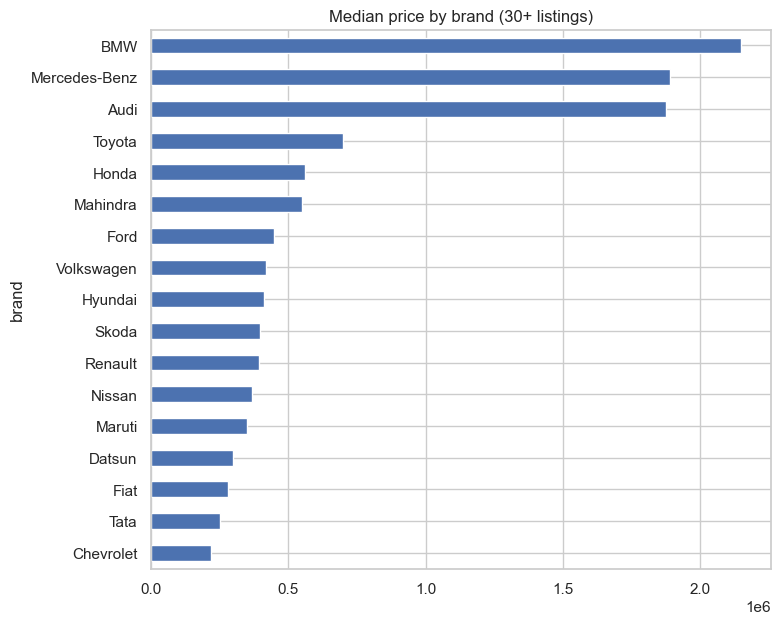

In [5]:
counts = df["brand"].value_counts()
top = counts[counts >= 30].index
med_brand = (df[df["brand"].isin(top)]
             .groupby("brand")["selling_price"].median().sort_values())
med_brand.plot(kind="barh", figsize=(8, 7), title="Median price by brand (30+ listings)")
plt.show()

### Median

The median is the middle value of an ordered dataset. Unlike the mean, the median is less affected by extreme values or outliers.

Because used-car prices can contain a small number of very expensive vehicles, the median is useful for comparing typical prices across brands and models.

### Brand Comparison at the Same Vehicle Age

To make brand comparisons more consistent, median selling prices are also compared among cars that are exactly five years old.

Comparing vehicles with the same age helps reduce the effect of depreciation when examining differences between brands.

In [6]:
five = df[(df["car_age"] == 5) & (df["brand"].isin(top))]
five.groupby("brand")["selling_price"].agg(["median","count"]).sort_values("median", ascending=False).head(10)

,median,count
brand,,
BMW,2900000.0,5
Mercedes-Benz,2700000.0,7
Audi,2375000.0,3
Toyota,1575000.0,33
Mahindra,650000.0,87
Skoda,650000.0,7
Honda,625000.0,39
Nissan,622500.0,4
Hyundai,570000.0,127


## 3. Selling Price by Car Model

Car model provides more specific information than brand because different models from the same manufacturer can have substantially different price levels. Examining model-level prices helps determine whether including the model as a predictive feature can provide additional information beyond the brand.

In [7]:
print("Unique models:", df["model"].nunique())
print(df["model"].value_counts().head(15))

Unique models: 218
model
Swift Dzire    347
Swift          323
i20            302
Wagon R        243
Bolero         187
Verna          180
City           168
Alto           160
Scorpio        160
Grand i10      151
Indica         150
Innova         146
Ertiga         136
Alto 800       133
i10            132
Name: count, dtype: int64


### Comparing Common Models

Only models with at least 30 listings are included in the comparison. This minimum sample-size threshold reduces the influence of models represented by very few observations and makes the median-price comparisons more meaningful.

In [8]:
# Same brand, very different prices depending on the model
mc = df["model"].value_counts()
common = mc[mc >= 30].index
tmp = df[df["model"].isin(common)]
spread = (tmp.groupby(["brand", "model"])["selling_price"].median().reset_index())
brand_spread = spread.groupby("brand")["selling_price"].agg(["min", "max", "count"])
brand_spread = brand_spread[brand_spread["count"] >= 3].sort_values("max", ascending=False)
brand_spread.head(10)

,min,max,count
brand,,,
Toyota,400000.0,1725000.0,4
Hyundai,120000.0,1000000.0,11
Mahindra,300000.0,900000.0,6
Tata,140000.0,805500.0,7
Ford,250000.0,805000.0,4
Maruti,55000.0,800000.0,17
Honda,500000.0,600000.0,3


### Price Differences Between Models Within the Same Brand

Comparing models within the same brand helps determine whether the model itself contributes substantially to price differences.

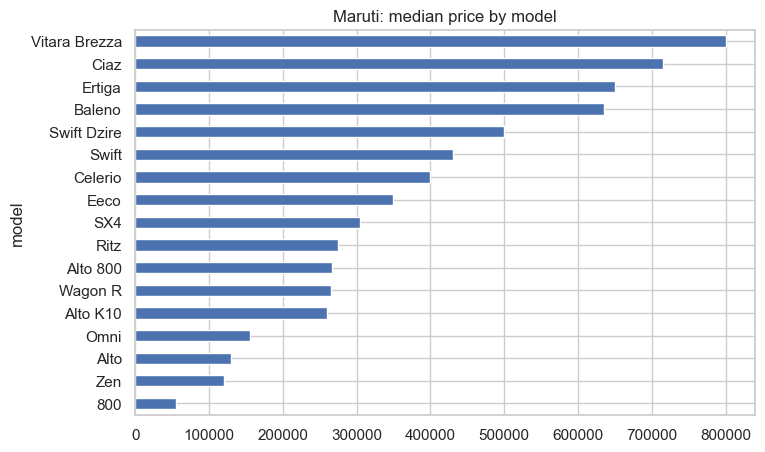

In [9]:
# Within one brand: median price of each common model
top_brand = df["brand"].value_counts().index[0]
(df[(df["brand"] == top_brand) & (df["model"].isin(common))]
 .groupby("model")["selling_price"].median().sort_values()
 .plot(kind="barh", figsize=(8, 5), title=f"{top_brand}: median price by model"))
plt.show()

## 4. Selling Price by Fuel Type and Transmission

Fuel type and transmission are categorical vehicle characteristics that may be associated with differences in used-car selling prices.

Boxplots are used to compare the distribution of log-transformed selling prices across the different categories. Median selling prices are also calculated to provide a direct numerical comparison between groups.

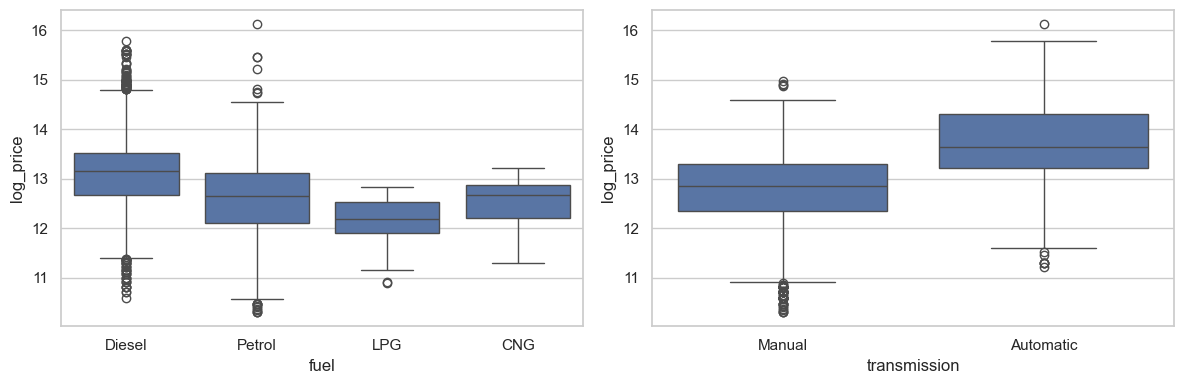

transmission
Automatic    845000.0
Manual       385000.0
Name: selling_price, dtype: float64
fuel
CNG       320000.0
Diesel    520000.0
LPG       195500.0
Petrol    310000.0
Name: selling_price, dtype: float64


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="fuel", y="log_price", ax=ax[0])
sns.boxplot(data=df, x="transmission", y="log_price", ax=ax[1])
plt.tight_layout()
plt.show()

print(df.groupby("transmission")["selling_price"].median())
print(df.groupby("fuel")["selling_price"].median())

## 5. Engine Characteristics and Selling Price

Engine size and maximum power are numerical vehicle characteristics that may be associated with selling price. Scatter plots are used to examine whether higher engine capacity or maximum power tends to occur with higher-priced vehicles.

**Scatter plot definition:** A scatter plot displays individual observations using two numerical variables, allowing relationships, trends, clusters, and unusual observations to be visually examined.

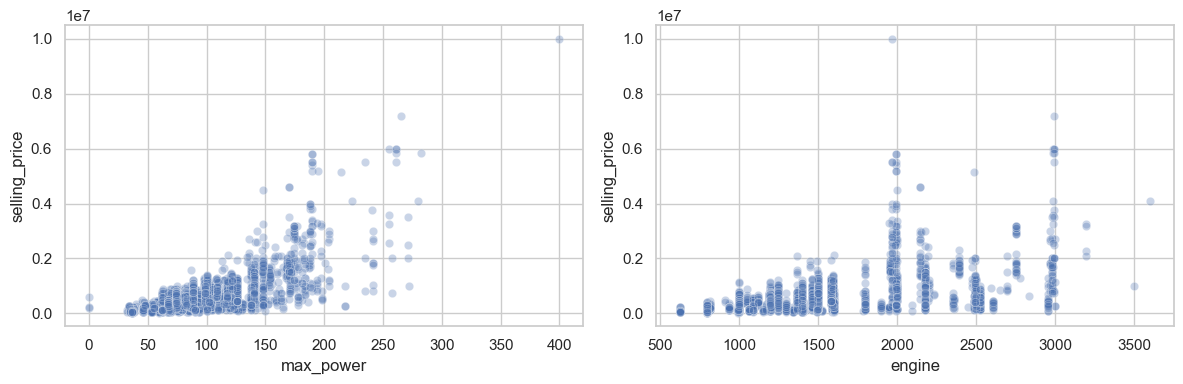

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="max_power", y="selling_price", alpha=0.3, ax=ax[0])
sns.scatterplot(data=df, x="engine", y="selling_price", alpha=0.3, ax=ax[1])
plt.tight_layout()
plt.show()

## 6. Correlation Between Numerical Features

Correlation measures the strength and direction of the linear relationship between two numerical variables. Its value ranges from -1 to +1. Values close to +1 indicate a strong positive linear relationship, values close to -1 indicate a strong negative linear relationship, and values close to 0 indicate a weak linear relationship.

Correlation indicates association, not causation.

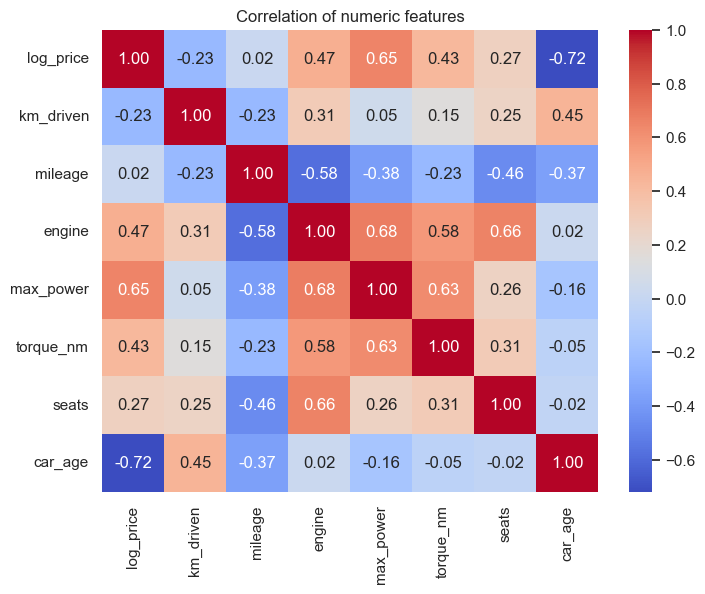

In [12]:
cols = ["log_price", "km_driven", "mileage", "engine",
        "max_power", "torque_nm", "seats", "car_age"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation of numeric features")
plt.show()

## 7. Key Insights

- Used-car selling prices are right-skewed, with a relatively small number of high-priced vehicles.
- The log transformation reduces the skewness of the selling-price distribution.
- Car age shows a relationship with selling price, with older vehicles generally having lower median prices.
- Median prices vary across brands, even when comparing vehicles of the same age.
- Different models within the same brand can have substantially different median prices, supporting the inclusion of both brand and model as predictive features.
- Fuel type and transmission show differences in selling-price distributions.
- Engine size and maximum power show observable relationships with selling price.
- The correlation analysis provides an initial view of relationships among numerical features and the target variable.